In [1]:

import numpy as np              # Import NumPy for numerical operations and handling arrays.
import pandas as pd             # Import Pandas for data manipulation and handling data in tabular form.
import matplotlib.pyplot as plt # Import Matplotlib's pyplot module for data visualization and plotting.
import scipy                    # Import SciPy, a scientific library for advanced mathematical operations.
from scipy import stats         # Import SciPy's stats module for statistical analysis and hypothesis testing.
from scipy import signal        # Import SciPy's signal processing module for filtering and signal analysis.
from scipy.signal import butter, filtfilt, find_peaks
import pywt                     # Import PyWavelets for wavelet transformations and signal denoising.
import seaborn as sns           # Import Seaborn for statistical data visualization and enhanced plot aesthetics.
import os                       # Import OS to interact with the operating system, e.g., for file handling.
import sys                      # Provides access to Python system-level functions, such as checking the Python version, managing command-line arguments, and modifying module paths.
import wfdb                     # Used to read, process, and visualize physiological waveform records

In [28]:
## Check Required Files

record_name = "105"
db_dir = r"C:\Users\jhala\OneDrive\Desktop\Internship\Datasets"
ecg = record.p_signal

record_path = os.path.join(db_dir, record_name)
required_files = [
    f"{record_path}.dat",
    f"{record_path}.hea",
    f"{record_path}.atr"
]

print("Checking required files:")


for file_path in required_files:
    if not os.path.exists(file_path):
        print(f"Missing: {file_path}")
    else:
        print(f"Found: {file_path}")

if not all(os.path.exists(file_path) for file_path in required_files):
    raise FileNotFoundError("One or more required files are missing. Please check the paths and try again.")

    

Checking required files:
Found: C:\Users\jhala\OneDrive\Desktop\Internship\Datasets\105.dat
Found: C:\Users\jhala\OneDrive\Desktop\Internship\Datasets\105.hea
Found: C:\Users\jhala\OneDrive\Desktop\Internship\Datasets\105.atr


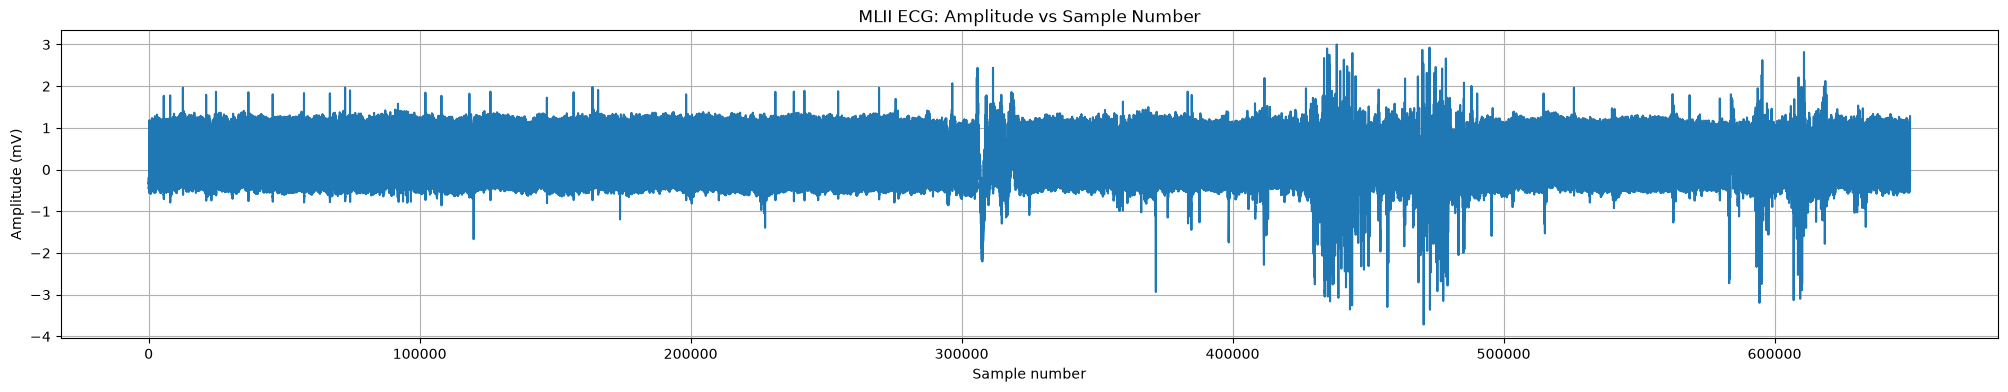

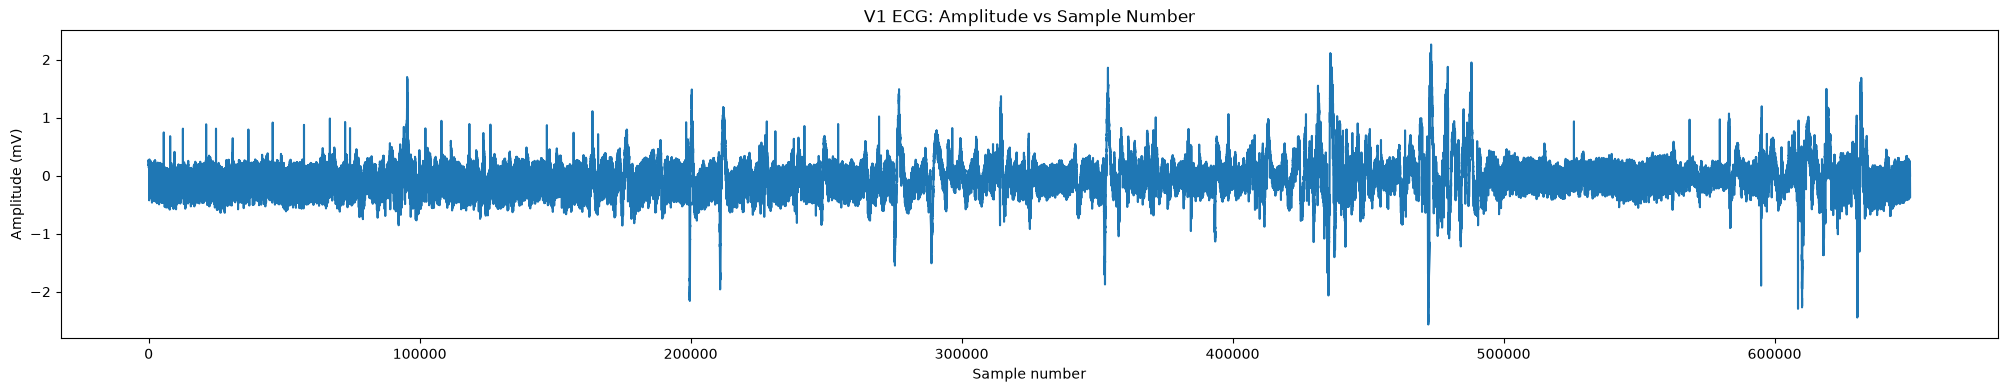

In [29]:
record = wfdb.rdrecord(record_path)

mlII = record.p_signal[:, 0]          # amplitude values, in mV
sample_number = np.arange(len(mlII))  # 0, 1, 2, ...

plt.figure(figsize=(25, 4))
plt.plot(sample_number, mlII)
plt.xlabel("Sample number")
plt.ylabel("Amplitude (mV)")
plt.title("MLII ECG: Amplitude vs Sample Number")
plt.grid()
plt.show()


v1 = record.p_signal[:, 1]
plt.figure(figsize=(25, 4))
plt.plot(np.arange(len(v1)), v1)
plt.xlabel("Sample number")
plt.ylabel("Amplitude (mV)")
plt.title("V1 ECG: Amplitude vs Sample Number")
plt.show()

In [12]:
# record = wfdb.rdrecord(record_path)
# annotation = wfdb.rdann(record_path,'atr')
# wfdb.plot_wfdb(record=record, annotation=annotation, title='ECG Signal with Annotations', time_units='seconds', figsize=(12, 4))

Text(0, 0.5, 'Amplitude (mV)')

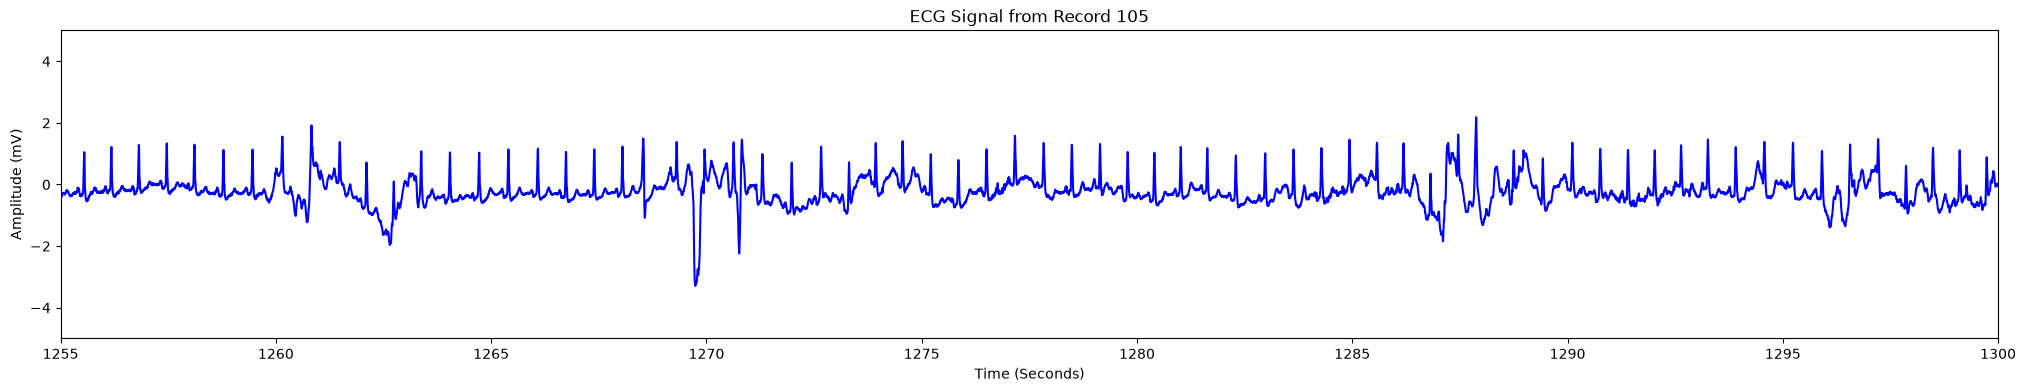

In [30]:
# Plot the ECG signal

fs = 360
t = np.arange(0, len(record.p_signal)) / fs # 

plt.figure(figsize=(25, 4))
plt.plot(t, record.p_signal[:,0], label='ECG Signal', color='blue') 
plt.title('ECG Signal from Record 105') 
# plt.xlim(400000/fs,500000/fs ) # dividing no. of samples with fs gives time  
plt.xlim(1255,1300)
plt.ylim(-5, 5)
plt.xlabel('Time (Seconds)')
plt.ylabel('Amplitude (mV)')    



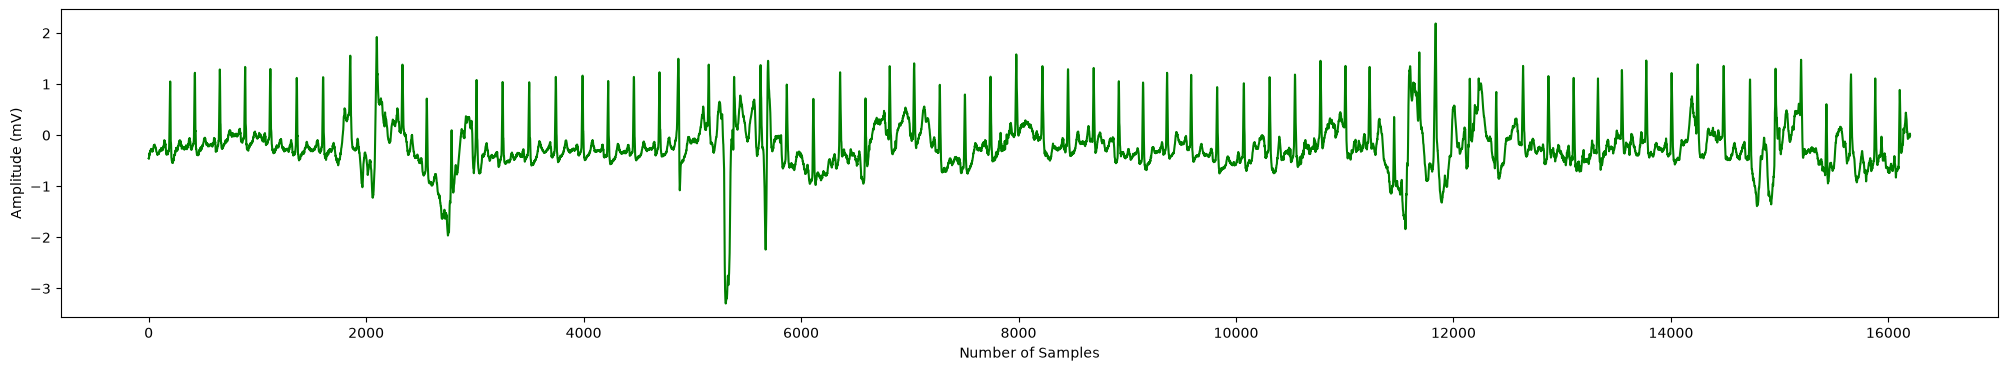

In [31]:
new_signal = record.p_signal[:,0] # (samples,channels) 
test_signal = new_signal[1255*fs:1300*fs] # multplication gives the no. of samples
header = wfdb.rdheader(record_path)
start_s = 1255
end_s = 1300
duration_seconds = end_s - start_s

plt.figure(figsize=(25, 4))
plt.xlabel('Number of Samples')
plt.ylabel('Amplitude (mV)')    
plt.plot(test_signal, color= 'green')

In [32]:
print(f"Record name             : {header.record_name}")
print(f"Sampling frequency      : {header.fs} Hz")
print(f"Number of ECG channels  : {header.n_sig}")
print(f"Signal names            : {header.sig_name}")
print(f"Signal units            : {header.units}")
print(f"Total number of samples : {header.sig_len}")
print(f"Total duration          : {header.sig_len / header.fs:.2f} seconds")
print(f"Total duration          : {header.sig_len / header.fs / 60:.2f} minutes")
print(f"ADC gain                : {header.adc_gain}")
print(f"Baseline                : {header.baseline}")
print(f"Comments                : {header.comments}")


Record name             : 105
Sampling frequency      : 360 Hz
Number of ECG channels  : 2
Signal names            : ['MLII', 'V1']
Signal units            : ['mV', 'mV']
Total number of samples : 650000
Total duration          : 1805.56 seconds
Total duration          : 30.09 minutes
ADC gain                : [200.0, 200.0]
Baseline                : [1024, 1024]
Comments                : ['73 F 1624 1629 x1', 'Digoxin, Nitropaste, Pronestyl', 'The PVCs are uniform.  The predominant feature of this tape is', 'high-grade noise and artifact.']


In [33]:
print(f"Signal duration      : {duration_seconds} seconds")
print(f"Loaded samples          : {ecg.shape[0]}")
print(f"ECG array shape         : {ecg.shape}")
print(f"Number of annotations   : {len(annotation.sample)}")

Signal duration      : 45 seconds
Loaded samples          : 650000
ECG array shape         : (650000, 2)
Number of annotations   : 2691


In [34]:
# Load the ECG record and its annotations

header = wfdb.rdheader(record_path)

sampling_frequency = header.fs

number_of_samples = int(sampling_frequency * duration_seconds)

record = wfdb.rdrecord(
    record_path,
    sampfrom=0,
    sampto=number_of_samples,
    physical=True 
)

annotation = wfdb.rdann(record_path,
extension='atr',
sampfrom=0,
sampto=number_of_samples,
shift_samps=True)

ecg = record.p_signal
time = np.arange(len(ecg)) / sampling_frequency

In [ ]:
print("\nFirst 10 ECG samples:")

for sample_index in range(min(10, ecg.shape[0])):
    signal_values = []

    for channel_index in range(ecg.shape[1]):
        signal_values.append(
            f"{record.sig_name[channel_index]}="
            f"{ecg[sample_index, channel_index]:.4f} "
            f"{record.units[channel_index]}"
        )

    print(
        f"Sample {sample_index:4d} | "
        f"Time = {time[sample_index]:.4f} s | "
        + " | ".join(signal_values)
    )
    


First 10 ECG samples:
Sample    0 | Time = 0.0000 s | MLII=-0.4450 mV | V1=0.2600 mV
Sample    1 | Time = 0.0028 s | MLII=-0.4450 mV | V1=0.2600 mV
Sample    2 | Time = 0.0056 s | MLII=-0.4450 mV | V1=0.2600 mV
Sample    3 | Time = 0.0083 s | MLII=-0.4450 mV | V1=0.2600 mV
Sample    4 | Time = 0.0111 s | MLII=-0.4450 mV | V1=0.2600 mV
Sample    5 | Time = 0.0139 s | MLII=-0.4450 mV | V1=0.2600 mV
Sample    6 | Time = 0.0167 s | MLII=-0.4450 mV | V1=0.2600 mV
Sample    7 | Time = 0.0194 s | MLII=-0.4450 mV | V1=0.2600 mV
Sample    8 | Time = 0.0222 s | MLII=-0.4500 mV | V1=0.2600 mV
Sample    9 | Time = 0.0250 s | MLII=-0.4300 mV | V1=0.2500 mV


In [35]:
print(
    f"{'No.':<6}"
    f"{'Sample':<10}"
    f"{'Time (s)':<12}"
    f"{'Symbol':<10}"
    f"{'Auxiliary note'}"
)

print("-" * 65)

for index, sample_number in enumerate(annotation.sample):
    symbol = annotation.symbol[index]
    auxiliary_note = annotation.aux_note[index]

    print(
        f"{index + 1:<6}"
        f"{sample_number:<10}"
        f"{sample_number / sampling_frequency:<12.4f}"
        f"{symbol:<10}"
        f"{auxiliary_note}"
    )

No.   Sample    Time (s)    Symbol    Auxiliary note
-----------------------------------------------------------------
1     67        0.1861      +         (N 
2     197       0.5472      N         
3     459       1.2750      N         
4     708       1.9667      N         
5     965       2.6806      N         
6     1222      3.3944      N         
7     1479      4.1083      N         
8     1741      4.8361      N         
9     2015      5.5972      N         
10    2287      6.3528      N         
11    2550      7.0833      N         
12    2803      7.7861      N         
13    3052      8.4778      N         
14    3303      9.1750      N         
15    3563      9.8972      N         
16    3835      10.6528     N         
17    4102      11.3944     N         
18    4371      12.1417     N         
19    4635      12.8750     N         
20    4901      13.6139     N         
21    5154      14.3167     N         
22    5407      15.0194     N         
23    5561      15.4

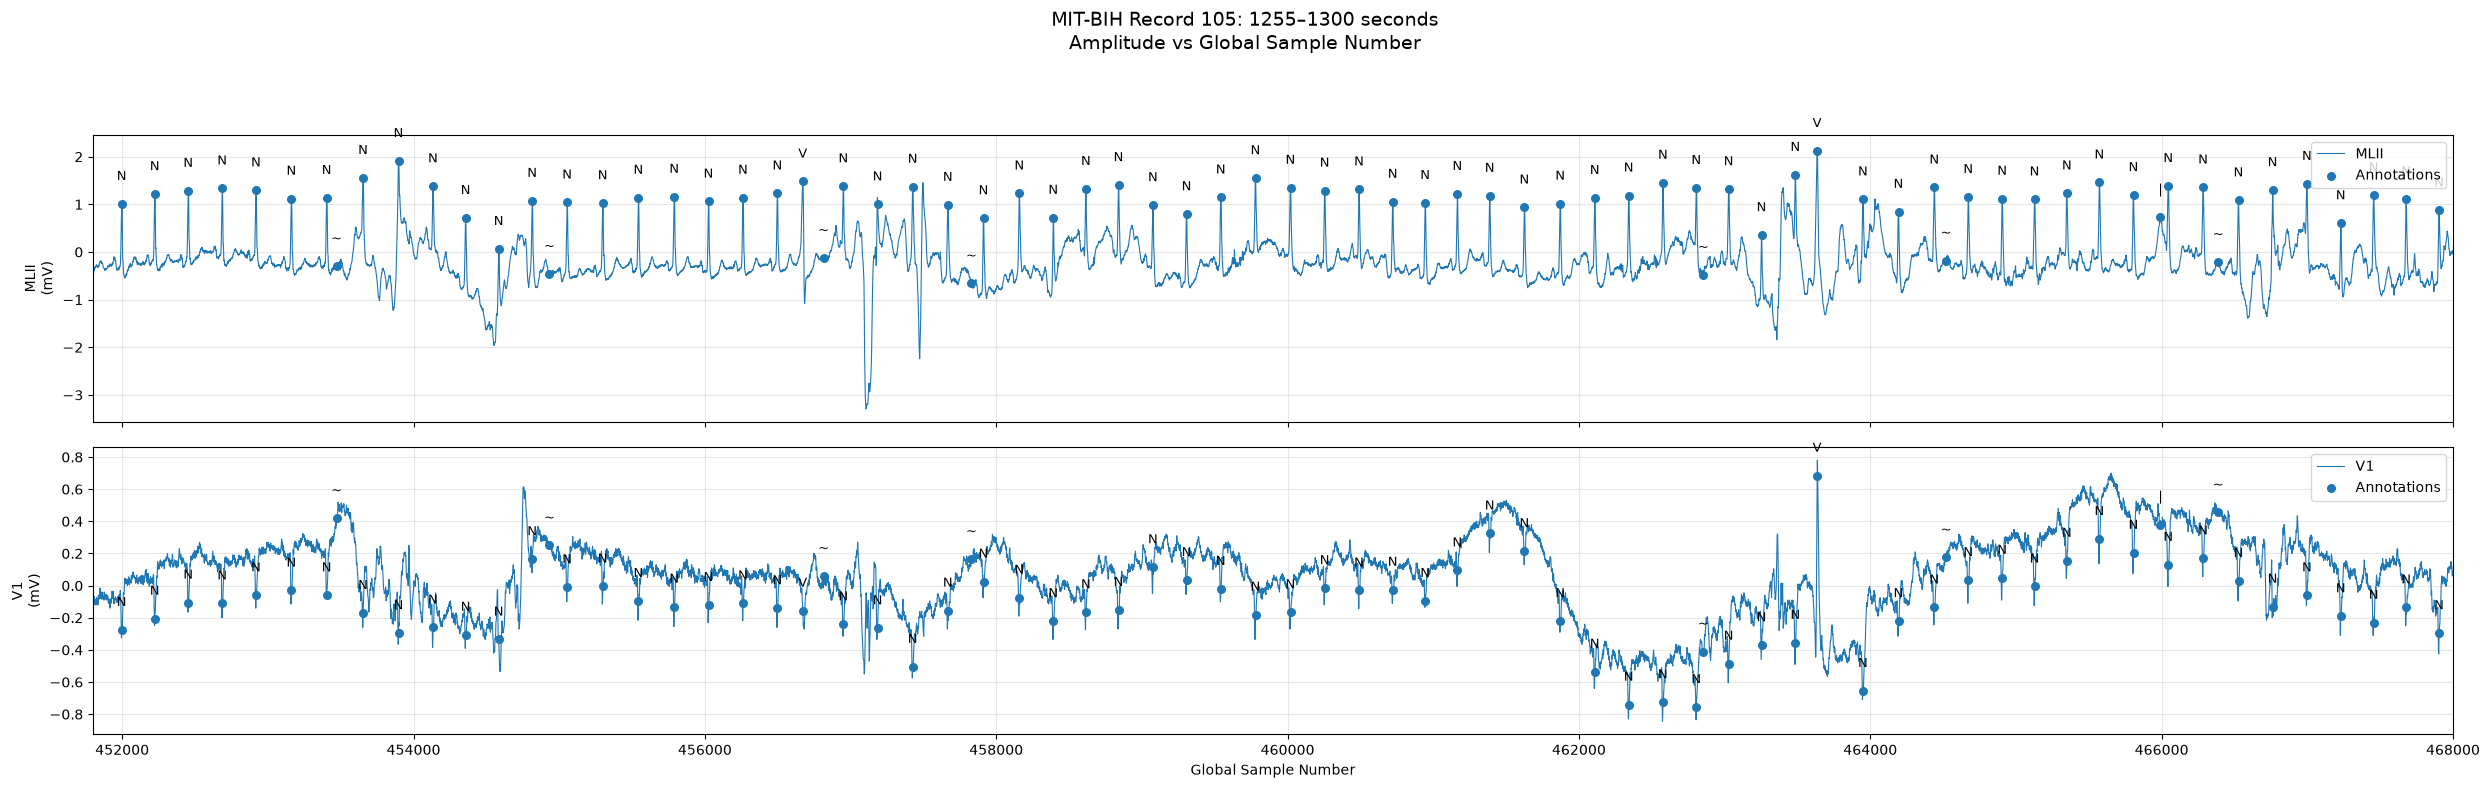

In [36]:
# Read record information
header = wfdb.rdheader(record_path)
sampling_frequency = header.fs

# Requested interval, in seconds
start_s = 1255
end_s = 1300
duration_seconds = end_s - start_s

# Convert requested times to global sample numbers
start_sample = int(start_s * sampling_frequency)
end_sample = int(end_s * sampling_frequency)

# Load only samples corresponding to 1255–1300 seconds
record = wfdb.rdrecord(
    record_path,
    sampfrom=start_sample,
    sampto=end_sample,
    physical=True
)

# Load annotations for exactly the same interval.
# shift_samps=True: annotation samples become local indices: 0, 1, 2, ...
annotation = wfdb.rdann(
    record_path,
    "atr",
    sampfrom=start_sample,
    sampto=end_sample,
    shift_samps=True
)

ecg = record.p_signal
number_of_channels = ecg.shape[1]

# Global sample positions: 451800 to 468000 for this example
sample_number = start_sample + np.arange(len(ecg))

annotation_samples = np.asarray(annotation.sample)
annotation_symbols = np.asarray(annotation.symbol, dtype=object)

fig, axes = plt.subplots(
    number_of_channels,
    1,
    figsize=(25, 4 * number_of_channels),
    sharex=True
)

axes = np.atleast_1d(axes)

for channel_index, ax in enumerate(axes):

    # MLII for channel 0; V1 for channel 1
    channel_signal = ecg[:, channel_index]

    # Plot: global sample number against amplitude
    ax.plot(
        sample_number,
        channel_signal,
        linewidth=0.8,
        label=record.sig_name[channel_index]
    )

    # Keep only annotations that are inside this loaded segment
    valid_mask = (
        (annotation_samples >= 0) &
        (annotation_samples < len(channel_signal))
    )

    valid_samples = annotation_samples[valid_mask]
    valid_symbols = annotation_symbols[valid_mask]

    # Convert local annotation indices to global sample numbers
    annotation_global_samples = start_sample + valid_samples
    annotation_amplitudes = channel_signal[valid_samples]

    # Plot annotation markers
    ax.scatter(
        annotation_global_samples,
        annotation_amplitudes,
        s=30,
        zorder=3,
        label="Annotations"
    )

    # Add annotation symbols
    text_offset = 0.08 * np.ptp(channel_signal)

    for x, symbol, amplitude in zip(
        annotation_global_samples,
        valid_symbols,
        annotation_amplitudes
    ):
        ax.text(
            x,
            amplitude + text_offset,
            symbol,
            fontsize=9,
            ha="center",
            va="bottom"
        )

    ax.set_ylabel(
        f"{record.sig_name[channel_index]}\n"
        f"({record.units[channel_index]})"
    )
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right")

axes[-1].set_xlabel("Global Sample Number")
axes[-1].set_xlim(start_sample, end_sample)

fig.suptitle(
    f"MIT-BIH Record {record_name}: {start_s}–{end_s} seconds\n"
    "Amplitude vs Global Sample Number",
    fontsize=14
)

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()


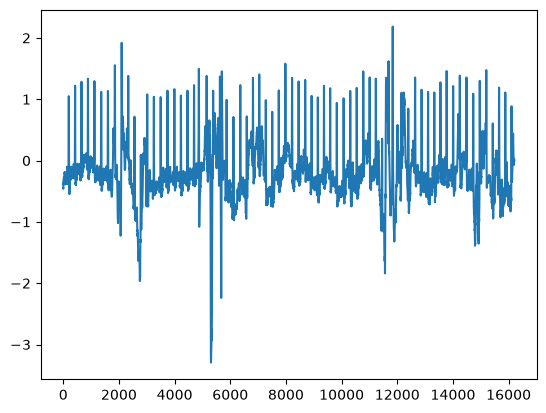

In [37]:
plt.plot(test_signal)
final_signal= new_signal[1255*fs:1300*fs]

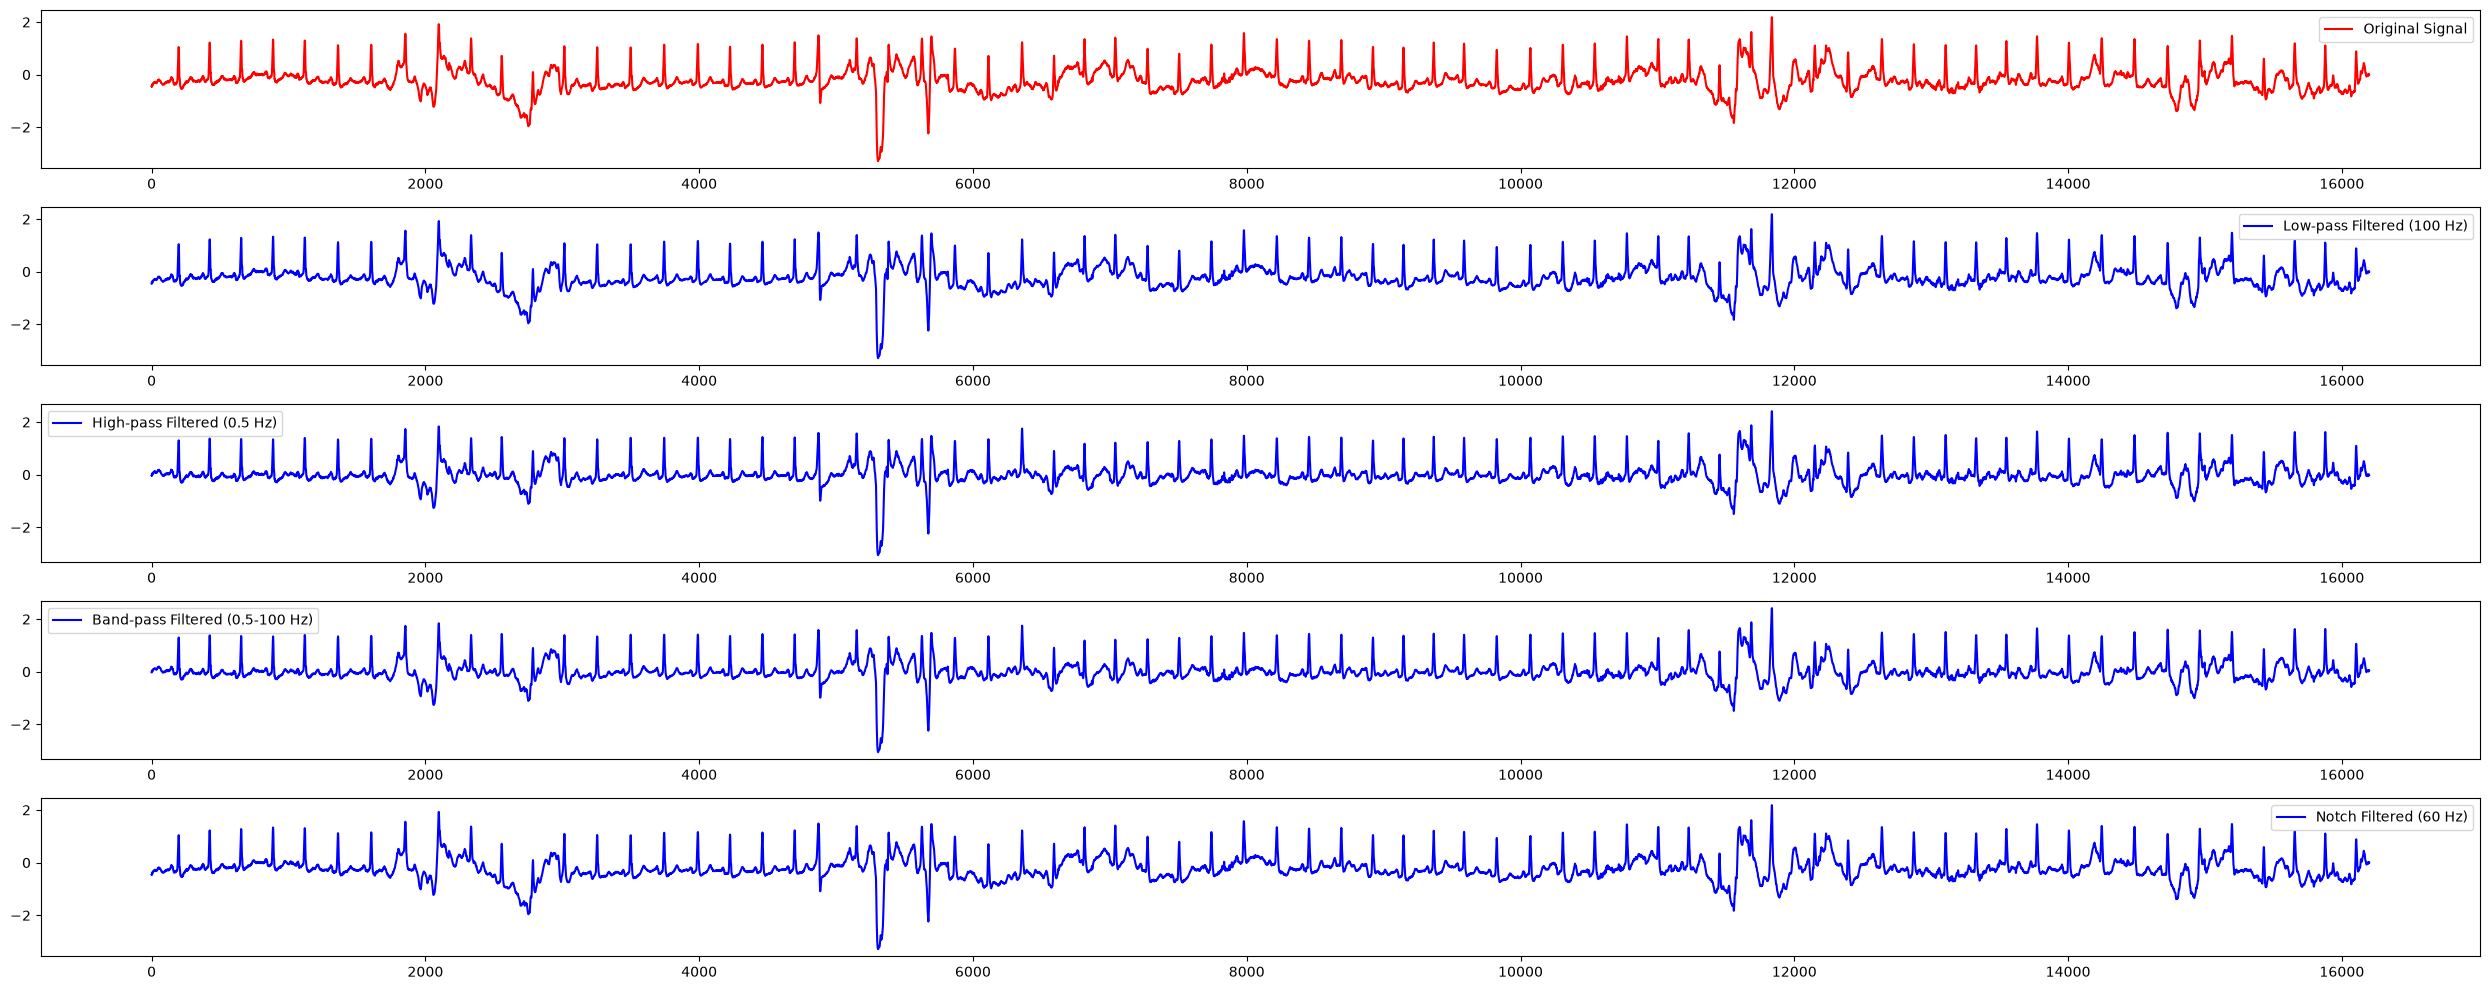

In [38]:
fs = 360 
start_s = 1255
end_s = 1300
duration_seconds = end_s - start_s

# Define Butterworth filter functions
def butter_lowpass(cutoff, fs, order=3):
    nyquist = 0.5 * fs # This calculates the Nyquist frequency, which is exactly half of your sampling rate. 
    normal_cutoff = cutoff / nyquist # As established by the Nyquist theorem, this is the absolute highest frequency your digital system can legally process without distortion.
    b, a = butter(order, normal_cutoff, btype='low', analog=False) # btype='low'; specifies you want a lowpass filter. Analog=False;explicitly tells the system to design a digital filter, not an analog hardware circuit.
    return b, a

def butter_highpass(cutoff, fs, order=3):
    nyquist = 0.5 * fs
    normal_cutoff = cutoff / nyquist
    b, a = butter(order, normal_cutoff, btype='high', analog=False)
    return b, a

def butter_bandpass(lowcut, highcut, fs, order=3):
    nyquist = 0.5 * fs
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = butter(order, [low, high], btype='band', analog=False)
    return b, a

def butter_notch(cutoff, fs, order=3):
    nyquist = 0.5 * fs
    low = (cutoff - 1) / nyquist  # Slightly below the cutoff
    high = (cutoff + 1) / nyquist  # Slightly above the cutoff
    b, a = butter(order, [low, high], btype='bandstop', analog=False)
    return b, a

# Filter application function
def apply_filter(data, b, a):
    y = filtfilt(b, a, data)
    return y


# Filter order
order = 4

# Low-pass filter
cutoff_low = 100
b, a = butter_lowpass(cutoff_low, fs, order)
low_filtered = apply_filter(final_signal, b, a)

# High-pass filter
cutoff_high = 0.5
b, a = butter_highpass(cutoff_high, fs, order)
high_filtered = apply_filter(final_signal, b, a)

# Band-pass filter
lowcut = 0.5
highcut = 100
b, a = butter_bandpass(lowcut, highcut, fs, order)
band_filtered = apply_filter(final_signal, b, a)

# Notch filter at 60 Hz
cutoff_notch = 60
b, a = butter_notch(cutoff_notch, fs, order)
notch_filtered = apply_filter(final_signal, b, a)

# Plotting the results
plt.figure(figsize=(25, 10))
plt.subplot(5, 1, 1)
plt.plot(final_signal, 'r', label="Original Signal")
plt.legend()
# plt.xlim(0, 100)

plt.subplot(5, 1, 2)
plt.plot(low_filtered, 'b', label="Low-pass Filtered (100 Hz)")
plt.legend()
# plt.xlim(0, 100)

plt.subplot(5, 1, 3)
plt.plot(high_filtered, 'b', label="High-pass Filtered (0.5 Hz)")
plt.legend()
# plt.xlim(10, 20)

plt.subplot(5, 1, 4)
plt.plot(band_filtered, 'b', label="Band-pass Filtered (0.5-100 Hz)")
plt.legend()
# plt.xlim(10, 20)

plt.subplot(5, 1, 5)
plt.plot(notch_filtered, 'b', label="Notch Filtered (60 Hz)")
plt.legend()
# plt.xlim(10, 20)

plt.tight_layout()
plt.show()

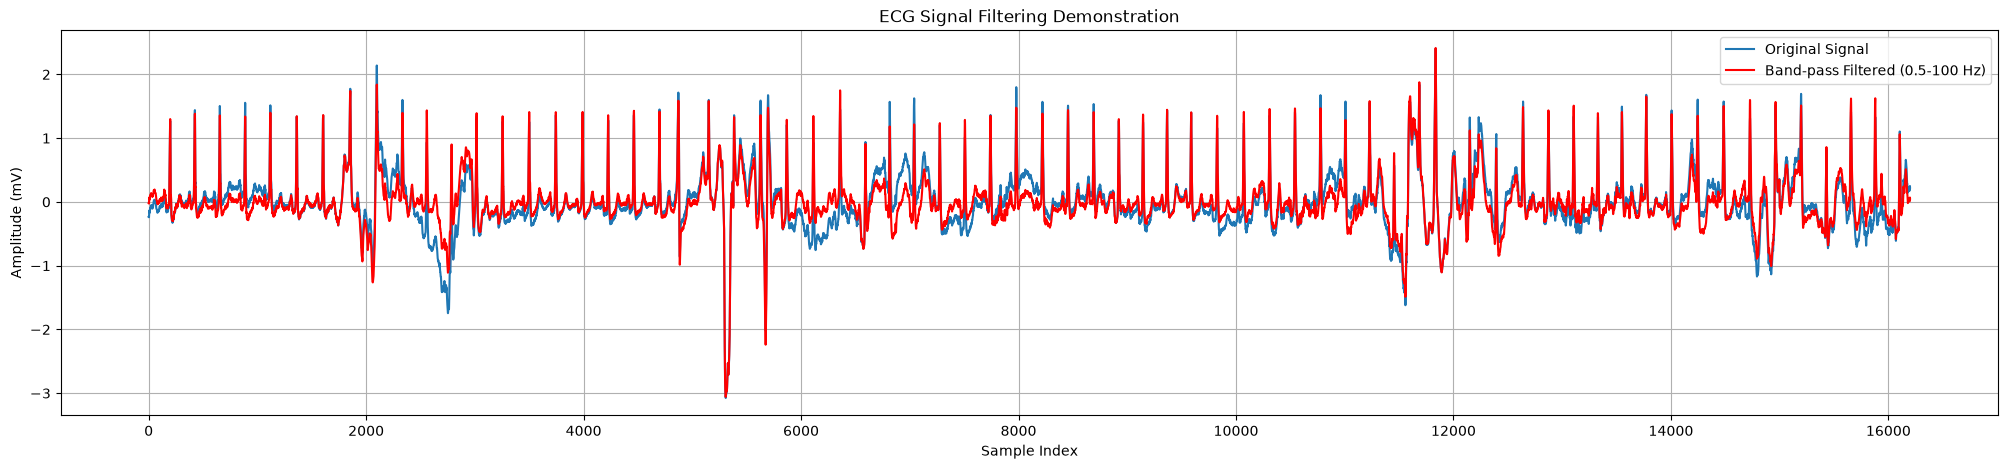

In [39]:
signal = ecg[:,0]

plt.figure(figsize=(25, 5)) #fig
plt.plot(signal-np.mean(signal), label='Original Signal')
# plt.plot(low_filtered-np.mean(low_filtered), label='Low-pass Filtered (100 Hz)')
# plt.plot(high_filtered-np.mean(high_filtered), label='High-pass Filtered (0.5 Hz)', color='cyan')   # important to remove baseline wander
plt.plot(band_filtered-np.mean(band_filtered), label='Band-pass Filtered (0.5-100 Hz)', color='red')  # remove baseline wander and high frequency noise
# plt.plot(notch_filtered-np.mean(notch_filtered), label='Notch Filtered (60 Hz)')
plt.title('ECG Signal Filtering Demonstration') 
plt.xlabel('Sample Index')
plt.ylabel('Amplitude (mV)')        
plt.legend()
plt.grid()
plt.show()

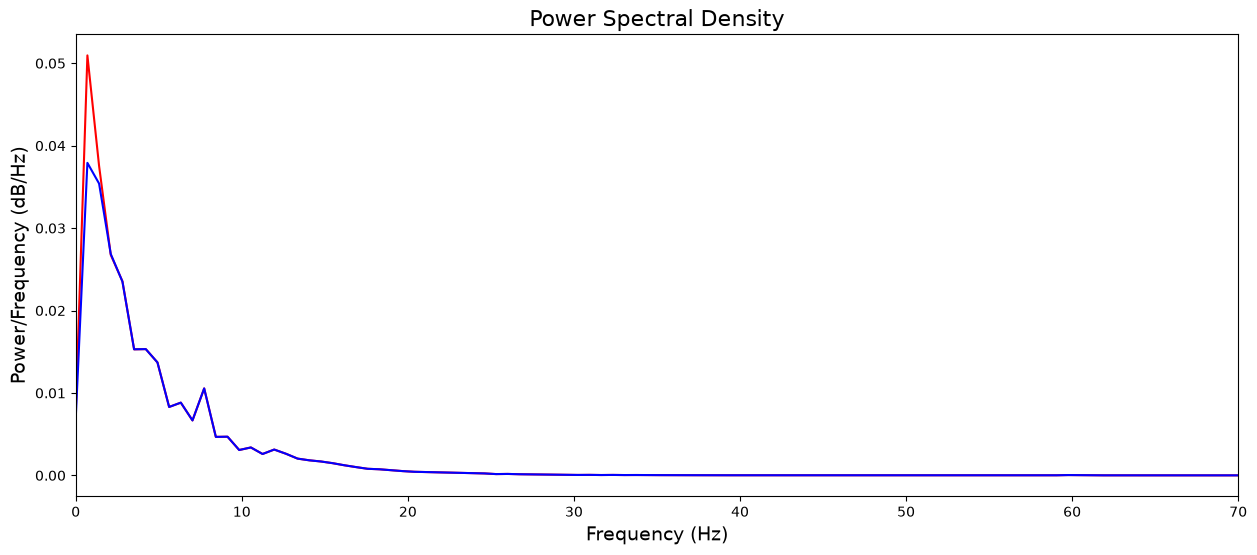

In [40]:
from scipy.signal import welch
signal = ecg[:,0]

frequencies, psd = welch(signal, fs, nperseg=512)
frequencies1, psd1 = welch(band_filtered, fs, nperseg=512)

plt.figure(figsize=(15, 6))
plt.plot(frequencies, psd, 'r')
plt.plot(frequencies1, psd1, 'b')
plt.xlabel('Frequency (Hz)', fontsize=14)
plt.ylabel('Power/Frequency (dB/Hz)', fontsize=14)
plt.title('Power Spectral Density', fontsize=16)
plt.xlim(0, 70)
plt.show()


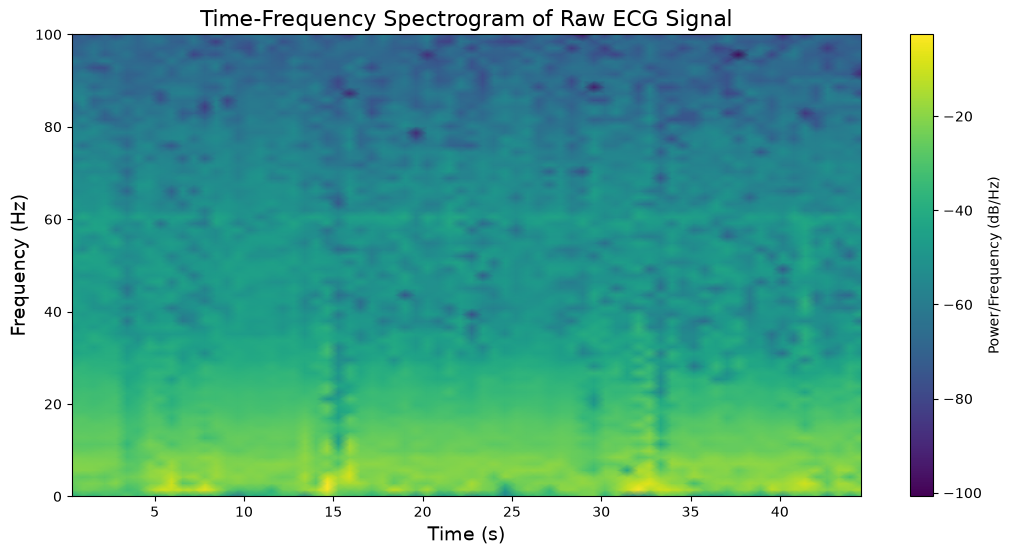

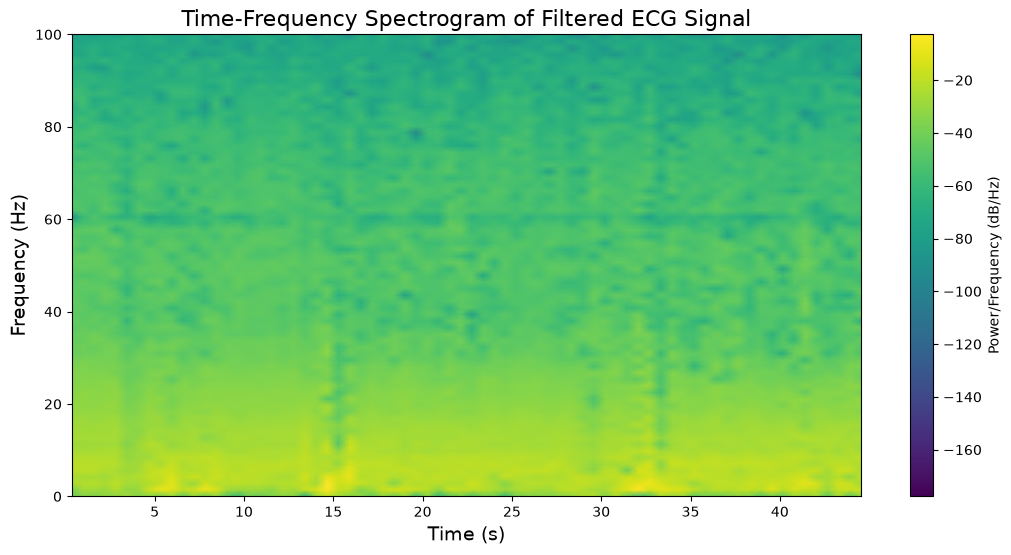

In [41]:
# !pip install pylance
import scipy.signal as sp_signal
from scipy.signal import spectrogram
from scipy.signal import ShortTimeFFT
from scipy.signal.windows import hann

signal = ecg[:,0]

frequencies, times, Sxx = sp_signal.spectrogram(signal, fs)

cutoff_notch = 60
b, a = butter_notch(cutoff_notch, fs, order)
notch_filtered = apply_filter(band_filtered, b, a)

frequencies1, times1, Sxx1 = sp_signal.spectrogram(notch_filtered, fs)

plt.figure(figsize=(28, 6))
plt.subplot(1, 2, 1)
plt.pcolormesh(times, frequencies, 10 * np.log10(Sxx), shading='gouraud')
plt.colorbar(label='Power/Frequency (dB/Hz)')
plt.ylabel('Frequency (Hz)', fontsize=14)
plt.xlabel('Time (s)', fontsize=14)
plt.title('Time-Frequency Spectrogram of Raw ECG Signal', fontsize=16)
plt.ylim(0, 100)
# plt.xlim(10, 40)
plt.show()

plt.figure(figsize=(28, 6))
plt.subplot(1, 2, 2)
plt.pcolormesh(times1, frequencies1, 10 * np.log10(Sxx1), shading='gouraud')
plt.colorbar(label='Power/Frequency (dB/Hz)')
plt.ylabel('Frequency (Hz)', fontsize=14)
plt.xlabel('Time (s)', fontsize=14)
plt.title('Time-Frequency Spectrogram of Filtered ECG Signal', fontsize=16)
plt.ylim(0, 100)
#plt.xlim(10, 40)
plt.show()

In [ ]:
import scipy.signal as iirnotch

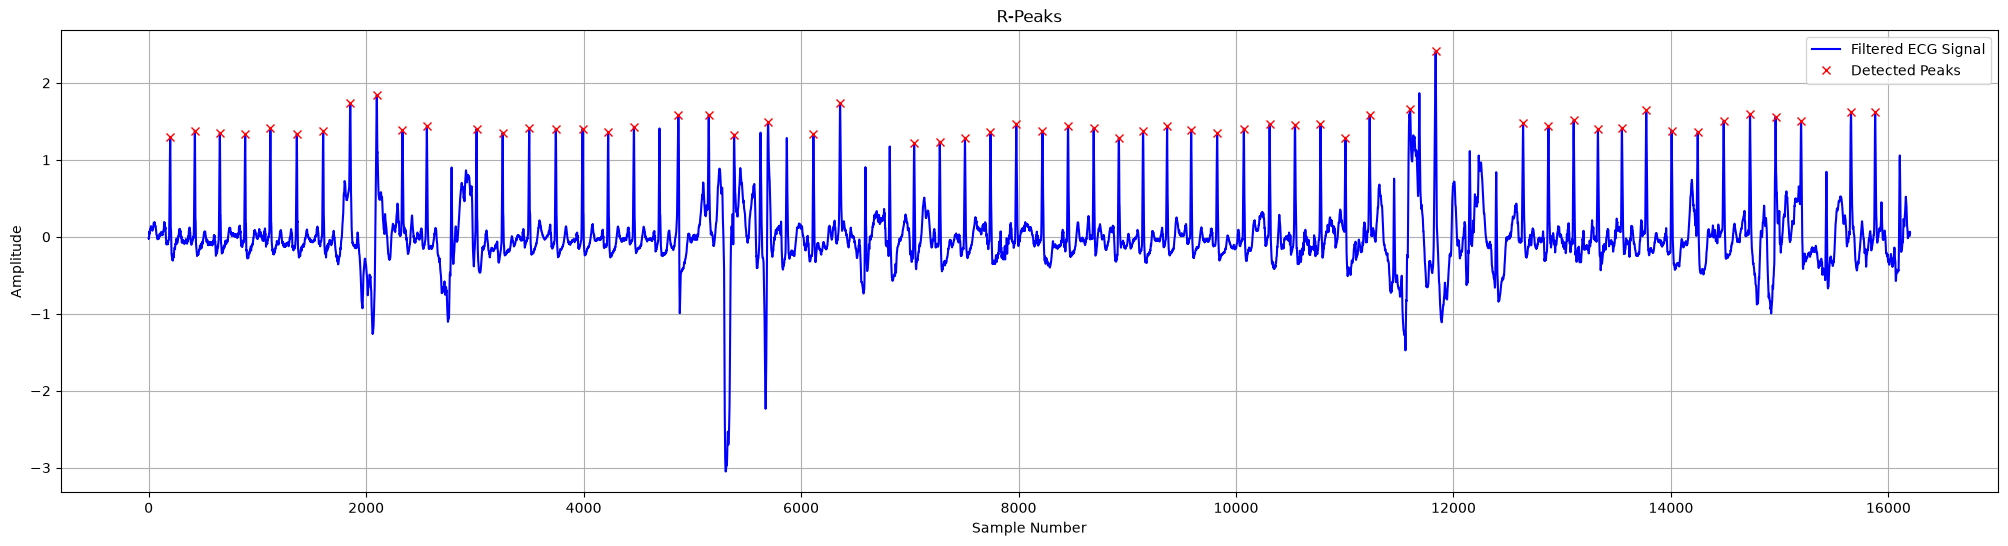

In [42]:
peaks, _ = find_peaks(notch_filtered, distance = int(fs* 0.5), height = 0.5* np.max(notch_filtered))

plt.figure(figsize=(25,6))
plt.plot(notch_filtered, label="Filtered ECG Signal", color="blue")
plt.plot(peaks, notch_filtered[peaks], "rx", label ="Detected Peaks")
plt.title("R-Peaks")
plt.xlabel("Sample Number")
plt.ylabel("Amplitude")
plt.legend()
plt.grid()
plt.show()

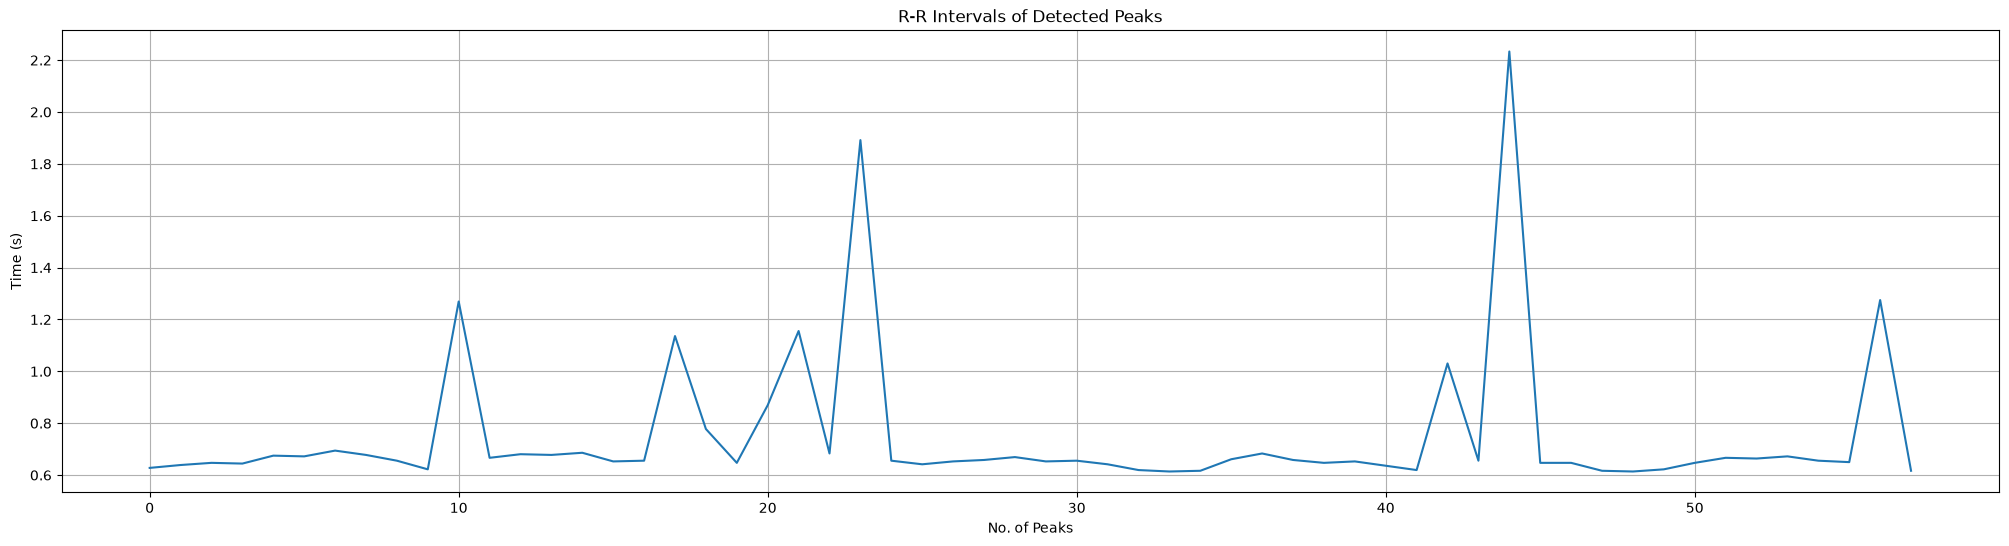

In [43]:

RRInterval = np.diff(peaks)* (1/fs)

plt.figure(figsize=(25, 6))
plt.plot(RRInterval)
plt.title("R-R Intervals of Detected Peaks")
plt.xlabel("No. of Peaks")
plt.ylabel("Time (s)")
plt.grid()
plt.show()

## Outcomes:
Most intervals are around 0.61–0.70 s.
This corresponds roughly to 86–98 beats/minute.
These parts are relatively regular.
There are several large spikes—approximately 1.0–1.3 s, one near 1.9 s, and one near 2.23 s.
If those are real consecutive R peaks, they represent unusually long gaps between detected ventricular beats.
For example, 2.23 s corresponds to about 60 / 2.23 ≈ 27 bpm for that interval.

The important outcome is: your detected beat sequence is mostly regular but has several long gaps/outliers.

In [44]:
Heart_Rate_Median = 60/np.median(RRInterval)
Heart_Rate_Mean = 60/np.mean(RRInterval)
print(f"Heart Rate: {Heart_Rate_Median:.2f}BPM")
print(f"Heart Rate: {Heart_Rate_Mean:.2f}BPM")

Heart Rate: 91.53BPM
Heart Rate: 79.90BPM


In [45]:
rr= RRInterval

mean_rr = np.mean(rr)
std_rr = np.std(rr, ddof=1)              # SDNN-like variation
cv_rr = std_rr / mean_rr * 100           # coefficient of variation (%)

successive_diff = np.diff(rr)
rmssd = np.sqrt(np.mean(successive_diff**2))
pnn50 = np.mean(np.abs(successive_diff) > 0.05) * 100

mean_hr = 60 / mean_rr

print(f"Mean RR interval : {mean_rr:.3f} s")
print(f"Mean heart rate  : {mean_hr:.1f} bpm")
print(f"RR standard dev. : {std_rr:.3f} s")
print(f"CV of RR         : {cv_rr:.1f} %")
print(f"RMSSD            : {rmssd:.3f} s")
print(f"pNN50            : {pnn50:.1f} %")

Mean RR interval : 0.751 s
Mean heart rate  : 79.9 bpm
RR standard dev. : 0.295 s
CV of RR         : 39.3 %
RMSSD            : 0.432 s
pNN50            : 28.1 %
